# 2. Exploratory Data Analysis (EDA)

2.1 Importing Required Libraries

In [ ]:
import kagglehub
import os


# Core libraries
import numpy as np
import pandas as pd

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
# Preprocessing
from sklearn.preprocessing import (
    MultiLabelBinarizer,
    OrdinalEncoder,
    LabelBinarizer,
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler
)

# Model selection
from sklearn.model_selection import train_test_split

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor


# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB


# Regression metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


# Classification metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc

)
# clustering
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Download latest version
path = kagglehub.dataset_download("rakeshkapilavai/ai-tool-usage-by-indian-college-students-2025")

print("Path to dataset files:", path)

100%|██████████| 88.5k/88.5k [00:00<00:00, 20.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rakeshkapilavai/ai-tool-usage-by-indian-college-students-2025/versions/1


2.2 Data Loading and Dataset Overview

In [ ]:
data_path = os.path.join(path, "Students.csv")
data = pd.read_csv(data_path)
data_original = data.copy(deep=True)


display(data.head())
print("\n"*2)
print("*"*200)
print("\n"*2)
display(data.columns)


,Student_Name,College_Name,Stream,Year_of_Study,AI_Tools_Used,Daily_Usage_Hours,Use_Cases,Trust_in_AI_Tools,Impact_on_Grades,Do_Professors_Allow_Use,Preferred_AI_Tool,Awareness_Level,Willing_to_Pay_for_Access,State,Device_Used,Internet_Access
0,Aarav,Indian Institute of Information Technology,Engineering,4,Gemini,0.9,"Assignments, Coding Help",2,2,No,Copilot,9,Yes,Uttar pradesh,Mobile,Poor
1,Vivaan,"Government Ram Bhajan Rai NES College, Jashpur",Commerce,2,ChatGPT,3.4,Learning new topics,3,-3,Yes,Other,6,No,Chhattisgarh,Laptop,Poor
2,Aditya,Dolphin PG Institute of BioMedical & Natural,Science,2,Copilot,3.6,"MCQ Practice, Projects",5,0,No,Gemini,1,No,Uttarakhand,Tablet,Poor
3,Vihaan,Shaheed Rajguru College of Applied Sciences for,Arts,2,Copilot,2.9,Content Writing,5,2,Yes,Gemini,5,No,Delhi ncr,Laptop,High
4,Arjun,Roorkee College of Engineering,Science,1,Gemini,0.9,"Doubt Solving, Resume Writing",1,3,Yes,Other,8,Yes,Uttarakhand,Laptop,Medium





********************************************************************************************************************************************************************************************************





Index(['Student_Name', 'College_Name', 'Stream', 'Year_of_Study',
       'AI_Tools_Used', 'Daily_Usage_Hours', 'Use_Cases', 'Trust_in_AI_Tools',
       'Impact_on_Grades', 'Do_Professors_Allow_Use', 'Preferred_AI_Tool',
       'Awareness_Level', 'Willing_to_Pay_for_Access', 'State', 'Device_Used',
       'Internet_Access'],
      dtype='object')

2.3 Data Cleaning


In [ ]:
print("The global info")
display(data.info())
print("\n"*2)
print("*"*200)
print("\n"*2)
print("The description")
data.describe()

The global info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3614 entries, 0 to 3613
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Student_Name               3614 non-null   object 
 1   College_Name               3614 non-null   object 
 2   Stream                     3614 non-null   object 
 3   Year_of_Study              3614 non-null   int64  
 4   AI_Tools_Used              3614 non-null   object 
 5   Daily_Usage_Hours          3614 non-null   float64
 6   Use_Cases                  3614 non-null   object 
 7   Trust_in_AI_Tools          3614 non-null   int64  
 8   Impact_on_Grades           3614 non-null   int64  
 9   Do_Professors_Allow_Use    3614 non-null   object 
 10  Preferred_AI_Tool          3614 non-null   object 
 11  Awareness_Level            3614 non-null   int64  
 12  Willing_to_Pay_for_Access  3614 non-null   object 
 13  State                      2000 

None




********************************************************************************************************************************************************************************************************



The description


,Year_of_Study,Daily_Usage_Hours,Trust_in_AI_Tools,Impact_on_Grades,Awareness_Level
count,3614.000000,3614.000000,3614.000000,3614.000000,3614.000000
mean,2.472883,2.559685,3.023243,0.003320,5.828445
std,1.107912,1.213319,1.436934,2.370706,2.925481
min,1.000000,0.500000,1.000000,-5.000000,1.000000
25%,2.000000,1.500000,2.000000,-2.000000,3.000000
50%,2.000000,2.600000,3.000000,0.000000,6.000000
75%,3.000000,3.600000,4.000000,2.000000,8.000000
max,4.000000,5.000000,5.000000,5.000000,10.000000


2.3.1 Handling Missing Values

In [ ]:
display(data.isna().sum())


missing_percentage = data_original[data_original.State.isna()].shape[0] / data_original.shape[0] * 100


print("\n"*2)
print("*"*200)
print("\n"*2)
print("The percentage of missing value :",missing_percentage)



,0
Student_Name,0
College_Name,0
Stream,0
Year_of_Study,0
AI_Tools_Used,0
Daily_Usage_Hours,0
Use_Cases,0
Trust_in_AI_Tools,0
Impact_on_Grades,0
Do_Professors_Allow_Use,0





********************************************************************************************************************************************************************************************************



The percentage of missing value : 44.659656889872714


As we can see the column State is missing **45%** of it's data. So it is better to drop the column entirely

In [ ]:
data = data.drop(axis=1, inplace=False, columns=['State'])
data.columns

Index(['Student_Name', 'College_Name', 'Stream', 'Year_of_Study',
       'AI_Tools_Used', 'Daily_Usage_Hours', 'Use_Cases', 'Trust_in_AI_Tools',
       'Impact_on_Grades', 'Do_Professors_Allow_Use', 'Preferred_AI_Tool',
       'Awareness_Level', 'Willing_to_Pay_for_Access', 'Device_Used',
       'Internet_Access'],
      dtype='object')

2.3.2 Removing Duplicate Records

In [ ]:
data.duplicated().sum()

np.int64(3)

In [ ]:
data.drop_duplicates(inplace=True)
data.duplicated().sum()

np.int64(0)

# 2.4 Univariate Analysis

2.4.1 Distribution of the Target Variable

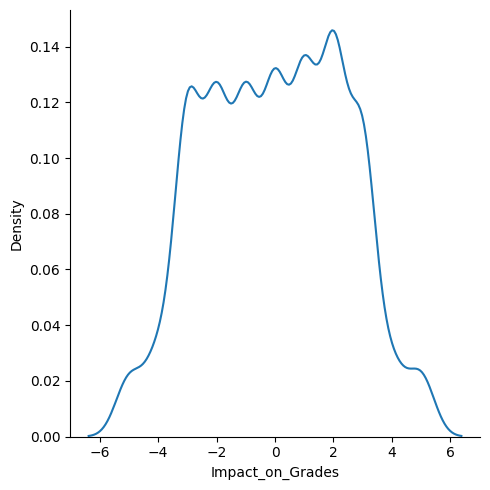

In [ ]:

sns.displot(data, x='Impact_on_Grades', kind='kde')

2.4.2 Distribution of Numerical Features

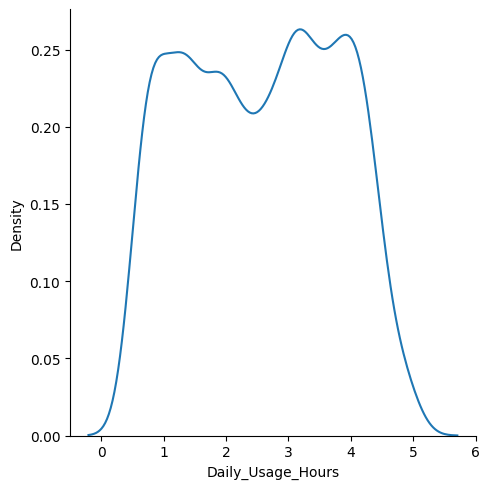

In [ ]:

sns.displot(data, x= 'Daily_Usage_Hours' , kind='kde')

2.4.3 Distribution of Categorical Features

<Axes: ylabel='AI_Tools_Used'>

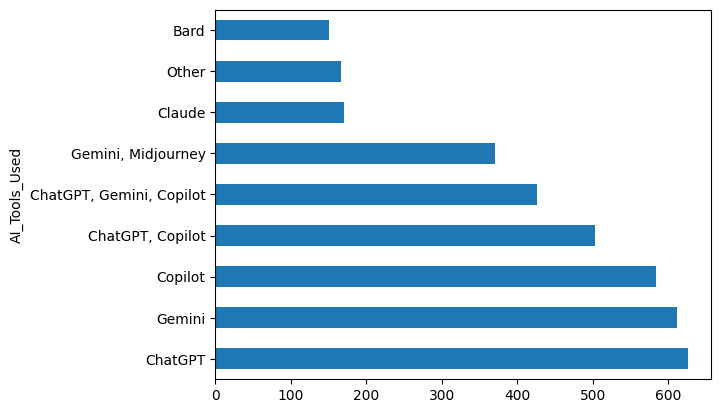

In [ ]:
count_AI_used =data['AI_Tools_Used'].value_counts()
count_AI_used.plot(kind='barh')

# 2.5 Multivariate Analysis

2.5.1 Relationship Between Internet Access Quality and Daily Usage Duration


np.float64(2.5291869918699184)

np.float64(2.60429252782194)

np.float64(2.542564559216385)

<Axes: xlabel='Internet_Access', ylabel='Daily_Usage_Hours'>

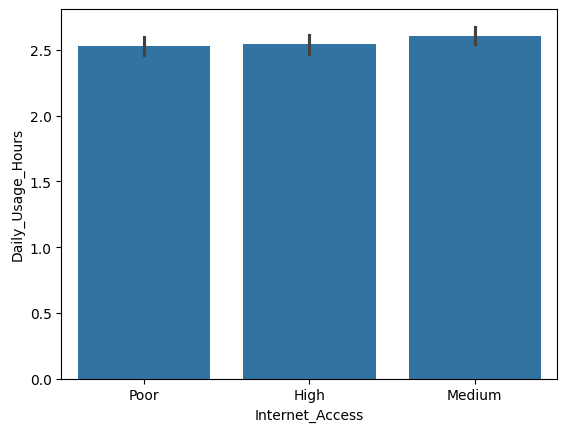

In [ ]:
mean_poor = data[data['Internet_Access'] == "Poor"]['Daily_Usage_Hours'].mean()
mean_medium = data[data['Internet_Access'] == "Medium"]['Daily_Usage_Hours'].mean()
mean_high = data[data['Internet_Access'] == "High"]['Daily_Usage_Hours'].mean()

display(mean_poor, mean_medium, mean_high)
sns.barplot(data, x='Internet_Access', y='Daily_Usage_Hours')

The bar chart shows that higher trust levels (4 and 5) are more frequent, especially level 5, indicating that most students have a generally positive trust in AI tools.

2.5.2 Analysis of Features vs Target Variable

<Axes: xlabel='Impact_on_Grades', ylabel='Daily_Usage_Hours'>

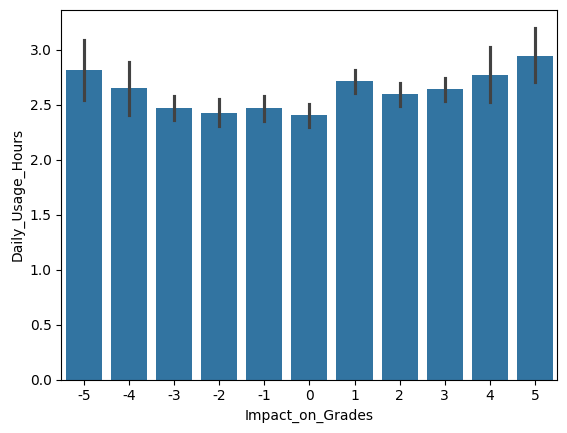

In [ ]:
sns.barplot(data, x='Impact_on_Grades', y='Daily_Usage_Hours')

2.5.3 Correlation Matrix and Heatmap (only Numerical values)

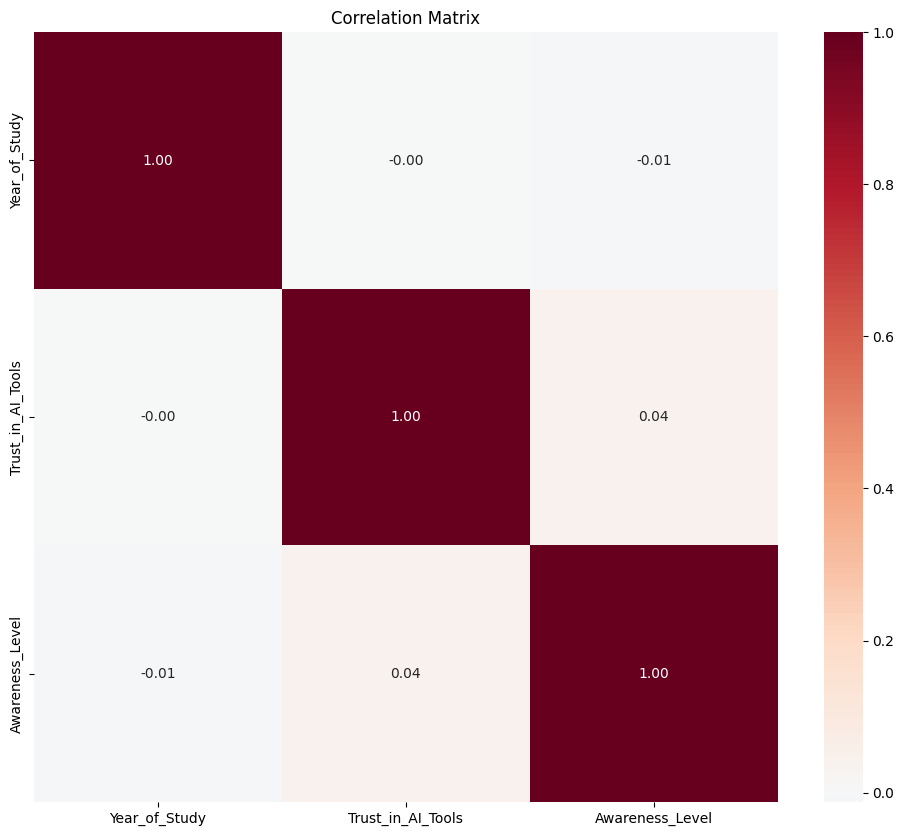

In [ ]:
coor=data[["Year_of_Study","Trust_in_AI_Tools","Awareness_Level"]].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(coor, annot=True, cmap='RdBu_r', center=0, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## 2.6 Outliner Dectetion

In [ ]:
def detect_outliner(series: pd.Series):
    mu = np.mean(series)
    sigma = np.std(series)
    z_scores = (series - mu)/sigma
    outliners = series[ abs(z_scores) > 3]
    return outliners

In [ ]:
numerical_columns = data_original.select_dtypes(include="number")
for col in numerical_columns.columns:
   n = detect_outliner(data_original[col]).shape[0]
   print(col, " ", str(n))


Year_of_Study   0
Daily_Usage_Hours   0
Trust_in_AI_Tools   0
Impact_on_Grades   0
Awareness_Level   0


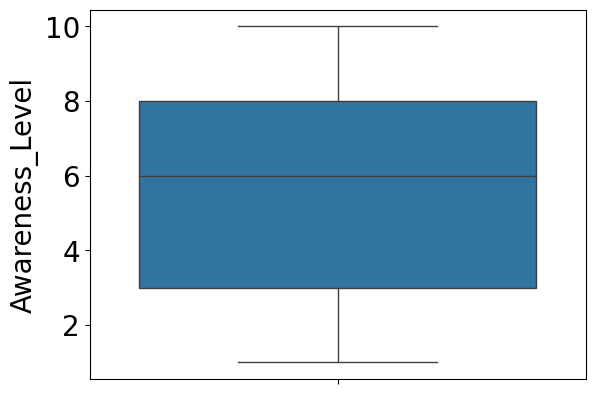

In [ ]:
sns.boxplot(y=data_original['Awareness_Level'])
plt.show()

# 3. Data Preparation and Feature Engineering


## 3.1 Encoding Strategies and Technical
Justifications

### 3.1.1 Multi-Label Binarization (MLB)

Use_Case_list before , the first code

In [ ]:
data['Use_Case_list'] = data['Use_Cases'].str.strip().str.split(',').apply(lambda x: ["Use_Cases_"+t.strip() for t in x])
# display(data.Use_Case_list.dtype)
# display(data.Use_Case_list.head())
mlb = MultiLabelBinarizer()
use_cases_encoded = pd.DataFrame(
    mlb.fit_transform(data["Use_Case_list"]),
    columns=mlb.classes_,
    index=data.index
)

use_cases_encoded["Use_Cases_Exam_Prep"] = (
    use_cases_encoded["Use_Cases_Exam Prep"] | use_cases_encoded["Use_Cases_Exam Preparation"]
).astype(int)

use_cases_encoded["Use_Cases_Projects"] = (
    use_cases_encoded["Use_Cases_Project Work"] | use_cases_encoded["Use_Cases_Projects"]
).astype(int)

use_cases_encoded.drop(
    columns=[
        "Use_Cases_Exam Prep",
        "Use_Cases_Exam Preparation",
        "Use_Cases_Project Work",
        "Use_Cases_Projects",
    ],
    inplace=True
)

data['Use_Case_Count'] = use_cases_encoded.sum(axis=1)
data = pd.concat([data, use_cases_encoded], axis=1)

display(use_cases_encoded.columns.shape)
display(use_cases_encoded.columns)
display(use_cases_encoded.head())


(9,)

Index(['Use_Cases_Assignments', 'Use_Cases_Coding Help',
       'Use_Cases_Content Writing', 'Use_Cases_Doubt Solving',
       'Use_Cases_Learning new topics', 'Use_Cases_MCQ Practice',
       'Use_Cases_Notes', 'Use_Cases_Resume Writing', 'Use_Cases_Exam_Prep'],
      dtype='object')

,Use_Cases_Assignments,Use_Cases_Coding Help,Use_Cases_Content Writing,Use_Cases_Doubt Solving,Use_Cases_Learning new topics,Use_Cases_MCQ Practice,Use_Cases_Notes,Use_Cases_Resume Writing,Use_Cases_Exam_Prep
0,1,1,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,1,0,0,0
3,0,0,1,0,0,0,0,0,0
4,0,0,0,1,0,0,0,1,0


AI_Tools_Used_list  , it is with the first code

In [ ]:
data['AI_Tools_Used_list'] = data['AI_Tools_Used'].str.strip().str.split(',').apply(lambda x: ["AI_Tools_Used_"+ t.strip() for t in x])
# display(data.Use_Case_list.dtype)
# display(data.Use_Case_list.head())
mlb = MultiLabelBinarizer()
ai_tools_used = pd.DataFrame(
    mlb.fit_transform(data["AI_Tools_Used_list"]),
    columns=mlb.classes_,
    index=data.index
)

data['AI_Tools_Count'] = use_cases_encoded.sum(axis=1)
data = pd.concat([data, ai_tools_used], axis=1)

display(ai_tools_used.columns.shape)
display(ai_tools_used.columns)
display(ai_tools_used.head())

(7,)

Index(['AI_Tools_Used_Bard', 'AI_Tools_Used_ChatGPT', 'AI_Tools_Used_Claude',
       'AI_Tools_Used_Copilot', 'AI_Tools_Used_Gemini',
       'AI_Tools_Used_Midjourney', 'AI_Tools_Used_Other'],
      dtype='object')

,AI_Tools_Used_Bard,AI_Tools_Used_ChatGPT,AI_Tools_Used_Claude,AI_Tools_Used_Copilot,AI_Tools_Used_Gemini,AI_Tools_Used_Midjourney,AI_Tools_Used_Other
0,0,0,0,0,1,0,0
1,0,1,0,0,0,0,0
2,0,0,0,1,0,0,0
3,0,0,0,1,0,0,0
4,0,0,0,0,1,0,0


### 3.1.2 One-Hot Encoding (OHE) and Mathematical Neutrality

In [ ]:

ohe = OneHotEncoder(sparse_output=False, drop='first')
encoded = ohe.fit_transform(data[['Stream']])
df_encoded = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(['Stream']))
data = pd.concat([data, df_encoded], axis=1)

ohe = OneHotEncoder(sparse_output=False, drop='first')
encoded = ohe.fit_transform(data[['Preferred_AI_Tool']])
df_encoded = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(['Preferred_AI_Tool']))
data = pd.concat([data, df_encoded], axis=1)

ohe = OneHotEncoder(sparse_output=False, drop='first')
encoded = ohe.fit_transform(data[['Device_Used']])
df_encoded = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(['Device_Used']))
data = pd.concat([data, df_encoded], axis=1)

data.columns

Index(['Student_Name', 'College_Name', 'Stream', 'Year_of_Study',
       'AI_Tools_Used', 'Daily_Usage_Hours', 'Use_Cases', 'Trust_in_AI_Tools',
       'Impact_on_Grades', 'Do_Professors_Allow_Use',
       ...
       'Stream_nan', 'Preferred_AI_Tool_ChatGPT', 'Preferred_AI_Tool_Claude',
       'Preferred_AI_Tool_Copilot', 'Preferred_AI_Tool_Gemini',
       'Preferred_AI_Tool_Other', 'Preferred_AI_Tool_nan',
       'Device_Used_Mobile', 'Device_Used_Tablet', 'Device_Used_nan'],
      dtype='object', length=145)







### 3.1.3 Ordinal Encoding and Hierarchical Integrity

In [ ]:
ordinalEncoder = OrdinalEncoder(categories=[["Poor", "Medium", "High"]])
data.dropna(inplace=True)
data['Internet_Access_Encoded'] = MinMaxScaler().fit_transform( ordinalEncoder.fit_transform(data[['Internet_Access']]) )
data.Internet_Access_Encoded.head()

,Internet_Access_Encoded
0,0.0
1,0.0
2,0.0
3,1.0
4,0.5


We didn't mention LabelBinarizer() so mention it to and use this code

In [ ]:
data['Do_Professors_Allow_Use_encoded'] = LabelBinarizer().fit_transform(data['Do_Professors_Allow_Use'])
data['Willing_to_Pay_for_Access_encoded'] = LabelBinarizer().fit_transform(data['Willing_to_Pay_for_Access'])
display(data.Do_Professors_Allow_Use_encoded.head())
print("*"*200)
display(data.Willing_to_Pay_for_Access_encoded.head())

,Do_Professors_Allow_Use_encoded
0,0
1,1
2,0
3,1
4,1


********************************************************************************************************************************************************************************************************


,Willing_to_Pay_for_Access_encoded
0,1
1,0
2,0
3,0
4,1


## 3.2 Standardization and Normalization: The
Choice of Scales

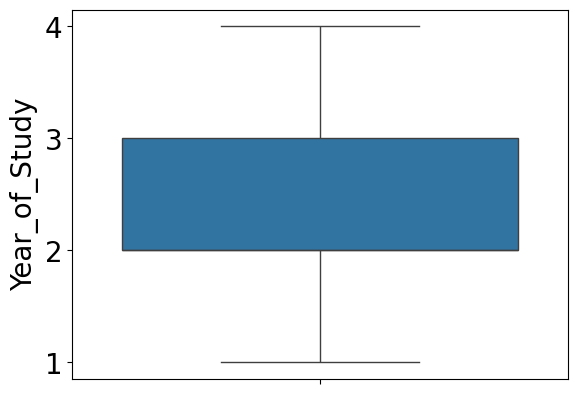

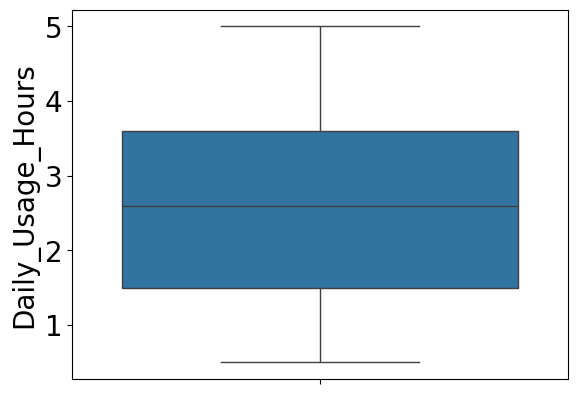

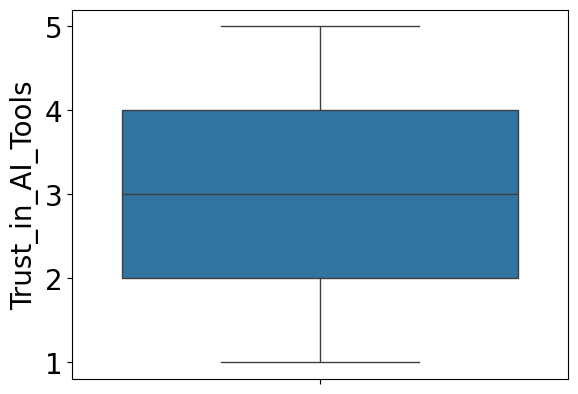

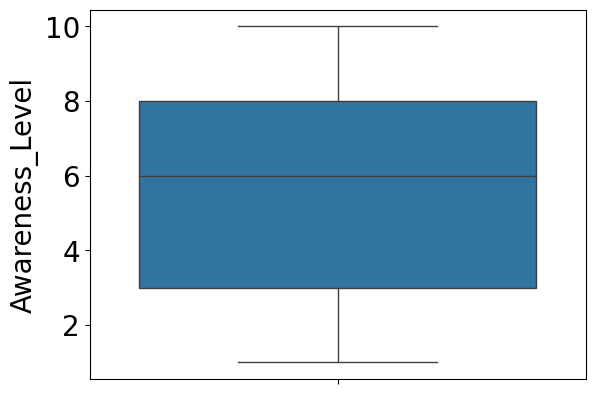

In [ ]:
sns.boxplot(y=data_original['Year_of_Study'])
plt.show()
sns.boxplot(y=data_original['Daily_Usage_Hours'])
plt.show()
sns.boxplot(y=data_original['Trust_in_AI_Tools'])
plt.show()
sns.boxplot(y=data_original['Awareness_Level'])
plt.show()

In [ ]:
data['Year_of_Study_encoded'] = MinMaxScaler().fit_transform(data[['Year_of_Study']])
data['Daily_Usage_Hours_encoded'] = StandardScaler().fit_transform(data[['Daily_Usage_Hours']])
data['Trust_in_AI_Tools_encoded'] = MinMaxScaler().fit_transform(data[['Trust_in_AI_Tools']])
data['Awareness_Level_encoded'] = MinMaxScaler().fit_transform(data[['Awareness_Level']])

## 3.3 Feature Selection and Correlation Analysis

In [ ]:
data.columns

Index(['Student_Name', 'College_Name', 'Stream', 'Year_of_Study',
       'AI_Tools_Used', 'Daily_Usage_Hours', 'Use_Cases', 'Trust_in_AI_Tools',
       'Impact_on_Grades', 'Do_Professors_Allow_Use', 'Preferred_AI_Tool',
       'Awareness_Level', 'Willing_to_Pay_for_Access', 'Device_Used',
       'Internet_Access', 'Use_Case_list', 'Use_Case_Count',
       'Use_Cases_Assignments', 'Use_Cases_Coding Help',
       'Use_Cases_Content Writing', 'Use_Cases_Doubt Solving',
       'Use_Cases_Learning new topics', 'Use_Cases_MCQ Practice',
       'Use_Cases_Notes', 'Use_Cases_Resume Writing', 'Use_Cases_Exam_Prep',
       'AI_Tools_Used_list', 'AI_Tools_Count', 'AI_Tools_Used_Bard',
       'AI_Tools_Used_ChatGPT', 'AI_Tools_Used_Claude',
       'AI_Tools_Used_Copilot', 'AI_Tools_Used_Gemini',
       'AI_Tools_Used_Midjourney', 'AI_Tools_Used_Other', 'Stream_Arts',
       'Stream_Commerce', 'Stream_Engineering', 'Stream_Hotel-management',
       'Stream_Law', 'Stream_Management', 'Stream_Medical

In [ ]:
data_encoded = data.select_dtypes(include='number').copy(deep=True)
data_encoded.drop(columns= ['Year_of_Study', 'Daily_Usage_Hours', 'Trust_in_AI_Tools', 'Awareness_Level'])


,Impact_on_Grades,Use_Case_Count,Use_Cases_Assignments,Use_Cases_Coding Help,Use_Cases_Content Writing,Use_Cases_Doubt Solving,Use_Cases_Learning new topics,Use_Cases_MCQ Practice,Use_Cases_Notes,Use_Cases_Resume Writing,...,Device_Used_Mobile,Device_Used_Tablet,Device_Used_nan,Internet_Access_Encoded,Do_Professors_Allow_Use_encoded,Willing_to_Pay_for_Access_encoded,Year_of_Study_encoded,Daily_Usage_Hours_encoded,Trust_in_AI_Tools_encoded,Awareness_Level_encoded
0,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0,1,1.000000,-1.367732,0.25,0.888889
1,-3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1,0,0.333333,0.692236,0.50,0.555556
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0,0,0.333333,0.857034,1.00,0.000000
3,2.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1,0,0.333333,0.280243,1.00,0.444444
4,3.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.5,1,1,0.000000,-1.367732,0.00,0.777778
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3606,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1,0,0.000000,1.104230,1.00,0.666667
3607,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.5,1,0,0.000000,1.104230,1.00,0.666667
3608,2.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1,1,0.000000,1.104230,1.00,0.666667
3609,2.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1,0,0.000000,1.433825,0.25,0.111111


/tmp/ipython-input-3703535607.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=target_corr_disp.values, y=target_corr_disp.index, palette='coolwarm')


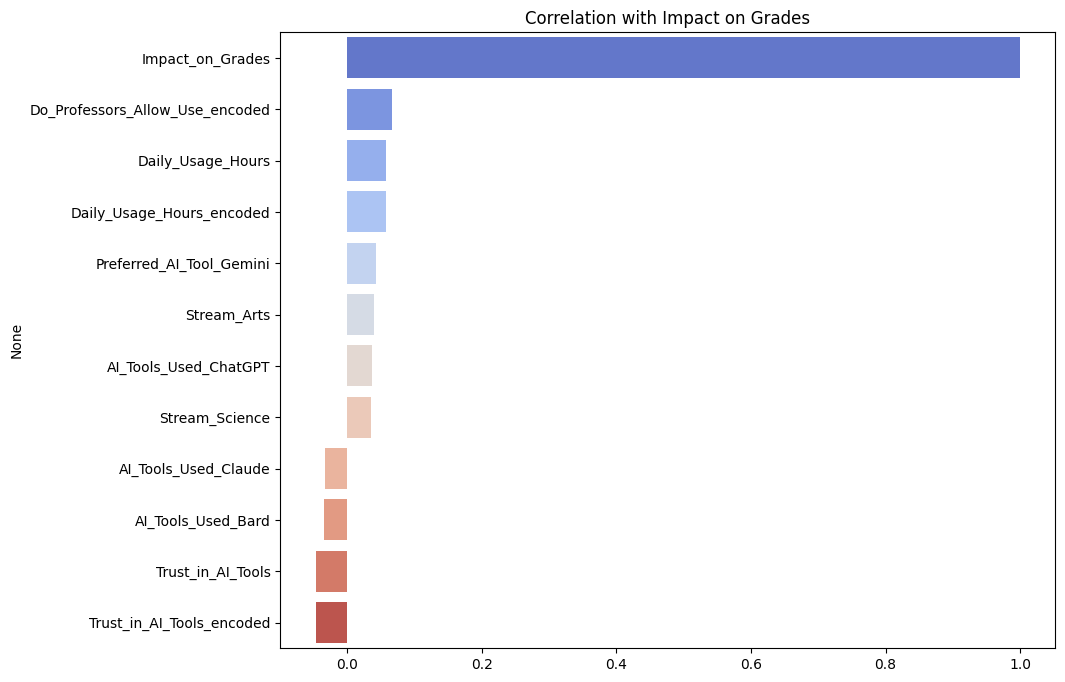

In [ ]:
target_corr = data_encoded.corr()['Impact_on_Grades'].sort_values(ascending=False)
target_corr_disp = target_corr[ np.abs(target_corr) > 0.03]

plt.figure(figsize=(10, 8))
sns.barplot(x=target_corr_disp.values, y=target_corr_disp.index, palette='coolwarm')
plt.title('Correlation with Impact on Grades')
plt.show()

correlation Matrice

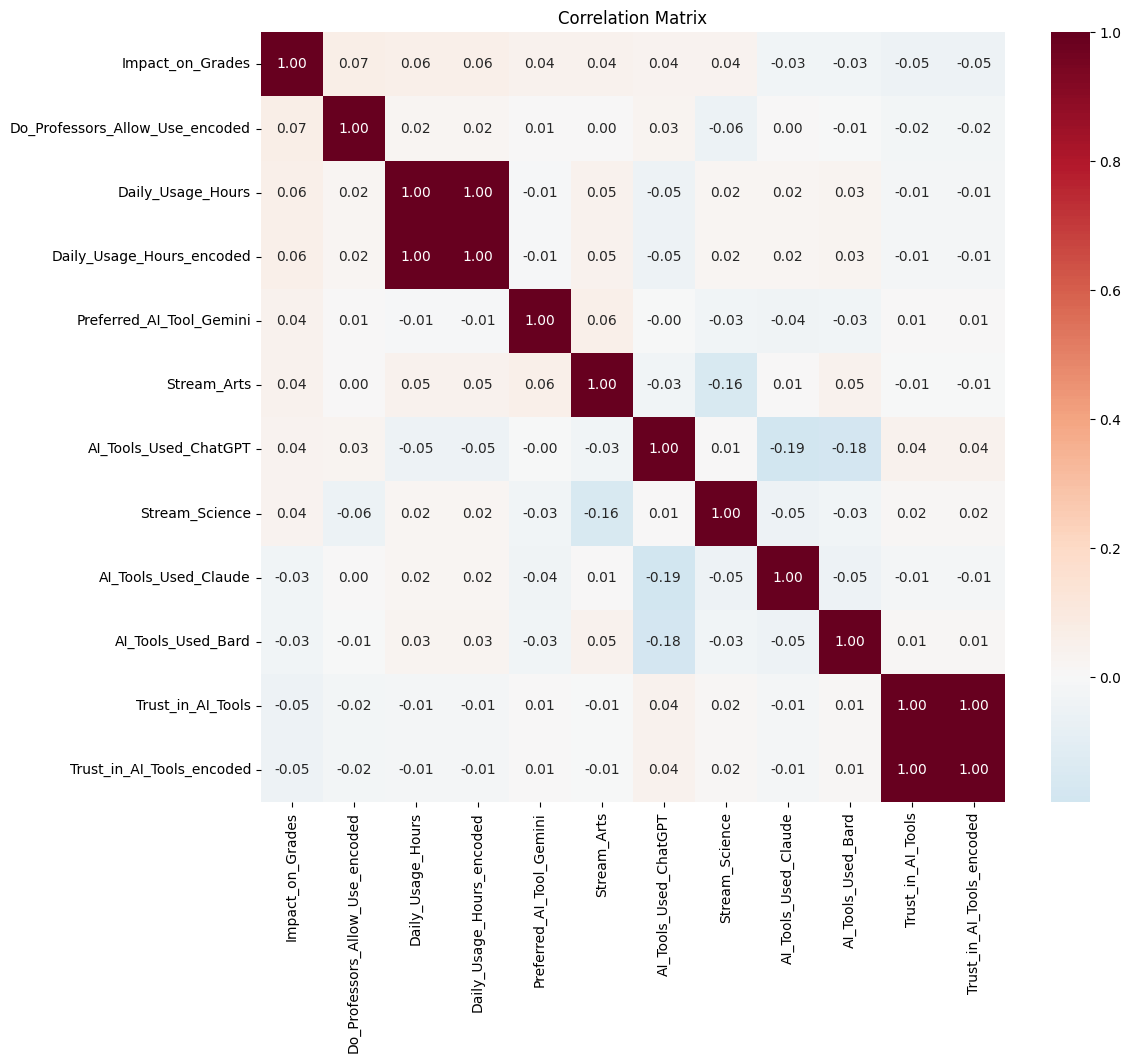

In [ ]:
top_features = target_corr[abs(target_corr) > 0.03].index
corr_matrix = data_encoded[top_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## 3.4 Validation via P-Value: Scientific Proof

In [ ]:
from scipy.stats import pearsonr
import pandas as pd

# Initialize a list to store correlation results
correlation_results = []

# Define the target variable
target = 'Impact_on_Grades'

# Iterate through all columns in the encoded dataframe
for col in data_encoded.columns:
    if col != target:
        # Calculate Pearson correlation and p-value
        # pearsonr returns (correlation_coefficient, p_value)
        corr, p_val = pearsonr(data_encoded[target], data_encoded[col])

        correlation_results.append({
            'Feature': col,
            'Correlation': round(corr, 4),
            'P-Value': round(p_val, 6),
            'Is_Significant': p_val < 0.05
        })

# Create a DataFrame to display the results
significance_df = pd.DataFrame(correlation_results)

# Sort by p-value to see the most statistically significant features first
significance_df = significance_df.sort_values(by='P-Value', ascending=True)

# Display only the significant features
significant_features = significance_df[significance_df['Is_Significant'] == True ]
print("Statistically Significant Features (p < 0.05):")
display(significant_features)

Statistically Significant Features (p < 0.05):


/tmp/ipython-input-2022411960.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, p_val = pearsonr(data_encoded[target], data_encoded[col])


,Feature,Correlation,P-Value,Is_Significant
41,Do_Professors_Allow_Use_encoded,0.0670,0.000057,True
1,Daily_Usage_Hours,0.0579,0.000503,True
44,Daily_Usage_Hours_encoded,0.0579,0.000503,True
2,Trust_in_AI_Tools,-0.0474,0.004420,True
45,Trust_in_AI_Tools_encoded,-0.0474,0.004420,True
34,Preferred_AI_Tool_Gemini,0.0428,0.010132,True
22,Stream_Arts,0.0400,0.016355,True
16,AI_Tools_Used_ChatGPT,0.0370,0.026301,True
30,Stream_Science,0.0355,0.033028,True
15,AI_Tools_Used_Bard,-0.0341,0.040528,True


As we can see the correlation are weak yet very significant. The most significant are : `Do proffessors allow use ` and `daily usage hours`, they seem to indicate that students that use AI the more have on average better grades.
Students who trust AI have worst grades.
These variables only explain small part of the data


Exploration of Non-Linear Relationships ,
you can create some points for this

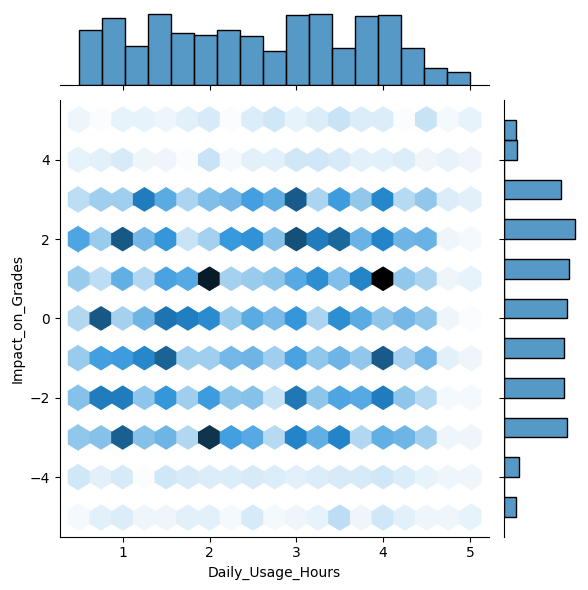

In [ ]:
sns.jointplot(data_encoded, x='Daily_Usage_Hours', y='Impact_on_Grades', kind='hex')

Use cases bar plot

 This too

<BarContainer object of 9 artists>

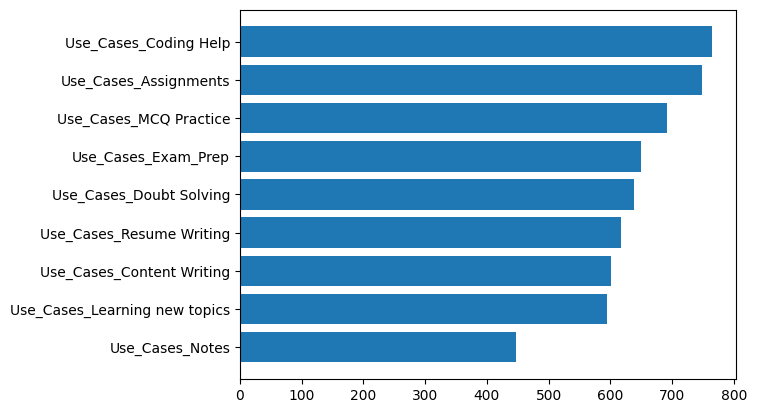

In [ ]:

cols = use_cases_encoded.columns
counts = np.zeros(shape=cols.shape)
for i in range(cols.shape[0]) :
    counts[i] = data[cols[i]].sum()

df = pd.DataFrame({'labels': cols, 'counts': counts}).sort_values(by='counts')

plt.barh(df['labels'], df['counts'])

Daily usage hours vs proffessor allow use

this too

np.float64(2.5884704519119355)

np.float64(2.5336875664187035)

<Axes: xlabel='Do_Professors_Allow_Use', ylabel='Daily_Usage_Hours'>

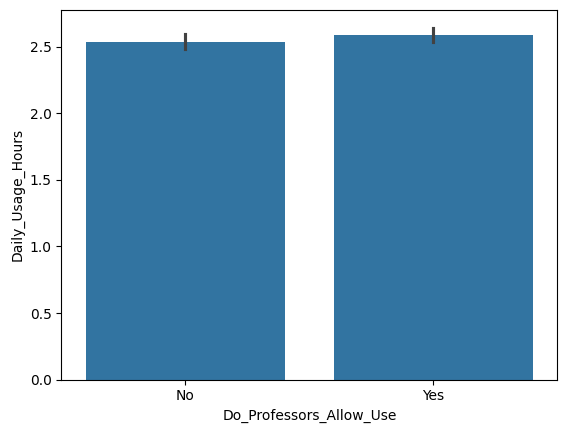

In [ ]:
average_for_allowed = data[data['Do_Professors_Allow_Use'] == "Yes"]['Daily_Usage_Hours'].mean()
average_for_forbidden = data[data['Do_Professors_Allow_Use'] == "No"]['Daily_Usage_Hours'].mean()
display(average_for_allowed,average_for_forbidden)
sns.barplot(data, x='Do_Professors_Allow_Use', y='Daily_Usage_Hours')

## 3.5 Final Optimization and Noise Reduction

In [ ]:
X = data_encoded.drop(columns=['Impact_on_Grades'])
y = data_encoded['Impact_on_Grades']
min_count = 0
display(min_count)
X = X.loc[:, (X.sum(axis=0) >= min_count)]
X.shape[1]

0

47

# 4. Machine Learning Models and Evaluation

## 4.1. Feature Selection and Model Configuration

In [ ]:
X = data_encoded.drop(columns=['Impact_on_Grades'])
y = data_encoded['Impact_on_Grades']
min_count = 0
display(min_count)
X = X.loc[:, (X.sum(axis=0) >= min_count)]
X.shape[1]

0

47

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


## 4.2. Regression Approach: Predicting Continuous Impact


### 4.2.1. Definition of Regression Models

In [ ]:

models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(random_state=42),
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42),
    "SVR": SVR(),
    "Guassian": GaussianNB()
}

### 4.2.2. Metrics and Results Analysis

In [ ]:
results = []
comparaison = pd.DataFrame()
comparaison['real_values'] = y_test.values

for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        "model": name,
        "MSE": mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred),

    })
    comparaison[name] = y_pred

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)
display(results_df)
display(comparaison)

,model,MSE,MAE,R2
1,RandomForest,4.160867,1.484307,0.262056
3,SVR,5.458389,1.896930,0.031936
0,LinearRegression,5.657857,1.996016,-0.003441
2,DecisionTreeRegressor,9.444598,1.957064,-0.675033
4,Guassian,21.853186,3.933518,-2.875739


,real_values,LinearRegression,RandomForest,DecisionTreeRegressor,SVR,Guassian
0,-1.0,-0.775520,0.91,-4.0,-0.510128,5.0
1,0.0,0.250221,-0.61,-1.0,0.916465,4.0
2,-4.0,1.110894,-0.34,1.0,1.529764,4.0
3,0.0,-0.026401,-0.03,0.0,-0.107670,4.0
4,-5.0,0.146339,0.14,4.0,0.309750,5.0
...,...,...,...,...,...,...
717,3.0,-0.159468,0.06,3.0,-0.693455,-3.0
718,-1.0,0.533864,-0.05,-1.0,0.954071,1.0
719,1.0,0.376457,-0.08,-2.0,0.012531,-5.0
720,-1.0,-0.085275,0.29,0.0,-0.241826,5.0


/tmp/ipython-input-3344035180.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="R2", y="model", data=results_df, palette="viridis")


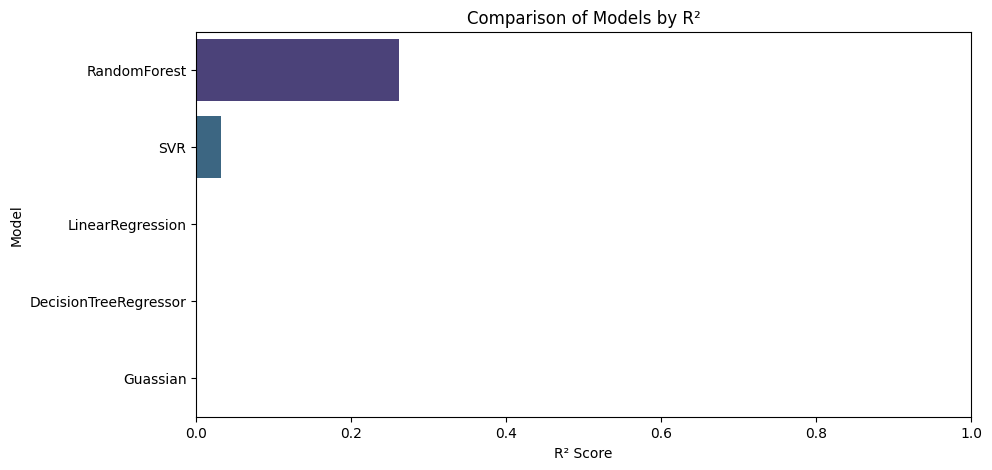

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.barplot(x="R2", y="model", data=results_df, palette="viridis")
plt.title("Comparison of Models by R²")
plt.xlabel("R² Score")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.show()

## 4.3. Multi-class Classification: Categorizing Grade Impact


### 4.3.1. Decision Tree Classifier

In [ ]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### 4.3.2. Multi-class Confusion Matrix Interpretation

0.4903047091412742

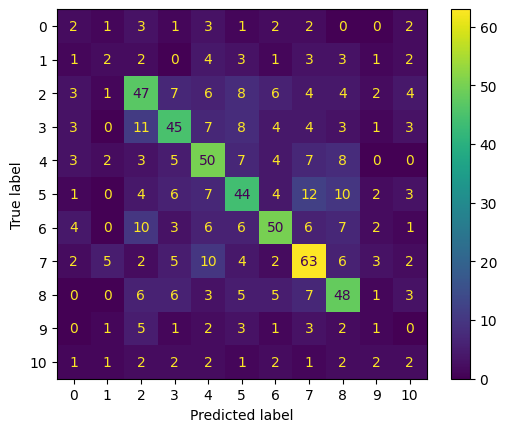

In [ ]:
y_pred = model.predict(X_test)
y_true = y_test

acc = accuracy_score(y_true, y_pred)
display(acc)
cm = confusion_matrix(y_true, y_pred)
cmd = ConfusionMatrixDisplay(confusion_matrix=cm)
cmd.plot()


## 4.4. Binary Classification: Success vs. Non Success


### 4.4.1. Model Justification

In [ ]:
models = {
    "RandomForest": RandomForestClassifier(random_state=42),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
    "SVC": SVC(),
    "Guassian": GaussianNB(),
}






### 4.4.2. Performance Metrics (Accuracy, F1-Score, Recall)

Explain this part

In [ ]:
y_train_class = y_train.apply(lambda x : 1 if x > 0 else 0)
y_test_class = y_test.apply(lambda x : 1 if x > 0 else 0)

In [ ]:


results = []
# Initialize dictionary with the real values
comparison_dict = {"real_values": y_test_class.values.flatten()}

for name, model in models.items():
    # Fit and Predict
    model.fit(X_train, y_train_class)
    y_pred = model.predict(X_test)

    # Store metrics - added 'weighted' to handle multi-class tasks safely
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_class, y_pred),
        "f1": f1_score(y_test_class, y_pred, average='weighted'),
        "recall": recall_score(y_test_class, y_pred, average='weighted'),
    })

    # Store predictions in dictionary
    comparison_dict[name] = y_pred

# Convert to DataFrames at the end
results_df = pd.DataFrame(results).sort_values(by="f1", ascending=False)
comparaison = pd.DataFrame(comparison_dict)

display(results_df)
display(comparaison)

,model,accuracy,f1,recall
0,RandomForest,0.774238,0.767743,0.774238
1,DecisionTreeClassifier,0.702216,0.702068,0.702216
2,SVC,0.620499,0.589463,0.620499
3,Guassian,0.574792,0.572336,0.574792


,real_values,RandomForest,DecisionTreeClassifier,SVC,Guassian
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,1,1
3,0,0,0,0,0
4,0,0,0,0,1
...,...,...,...,...,...
717,1,0,1,0,0
718,0,0,0,1,1
719,1,0,0,0,1
720,0,0,0,0,0


## 4.5. Detailed Confusion Matrix Interpretation (Binary)


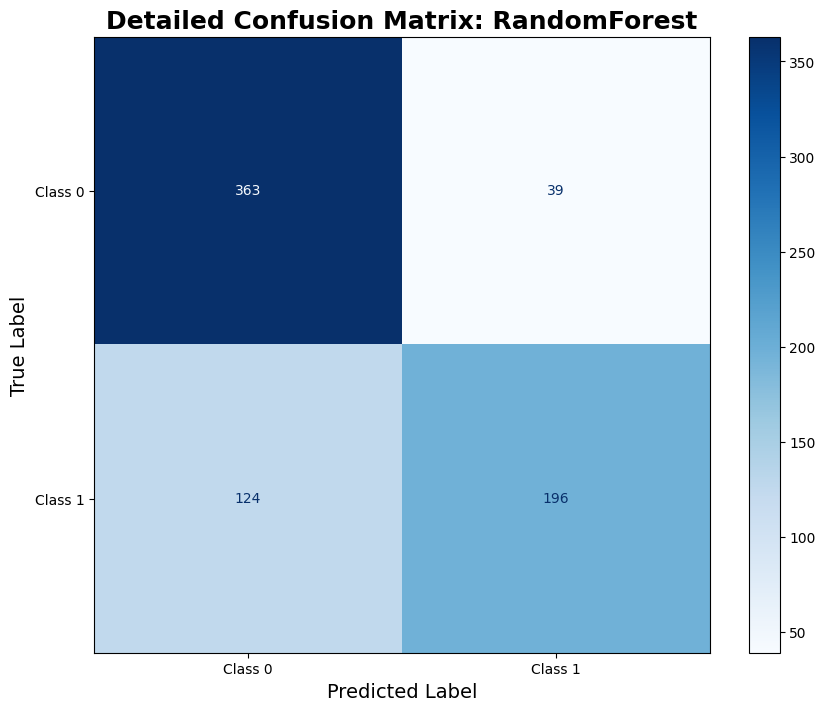

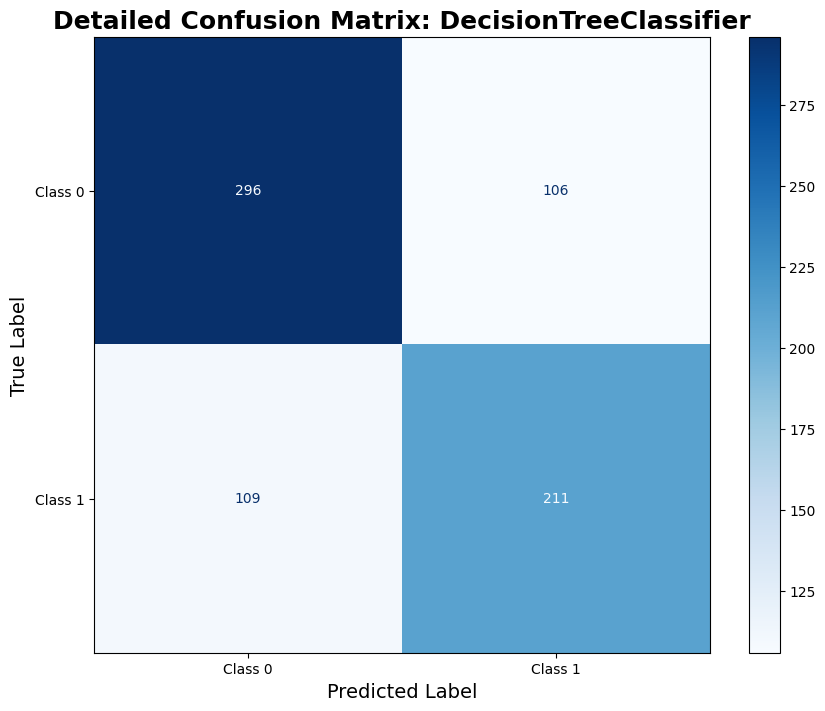

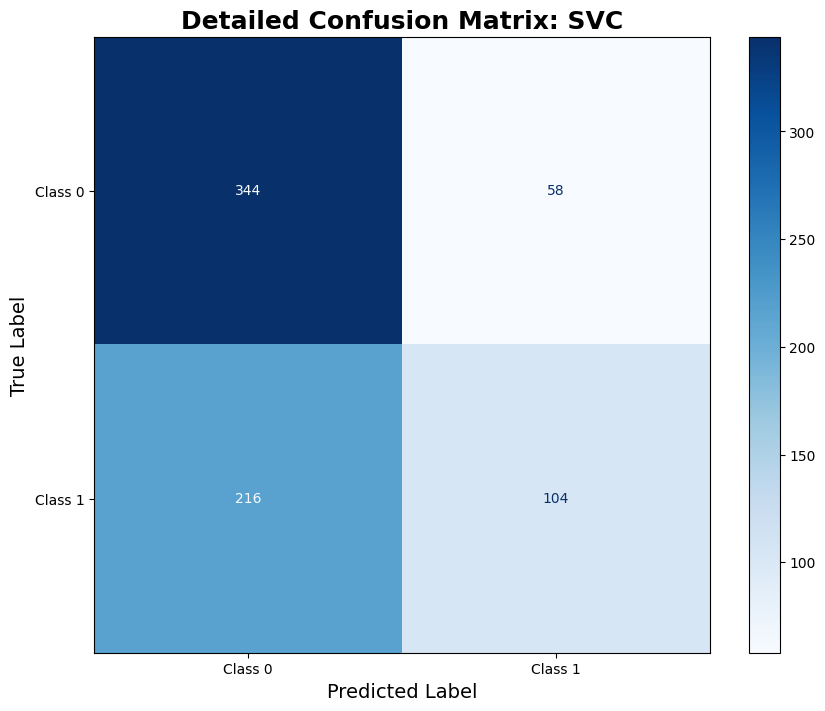

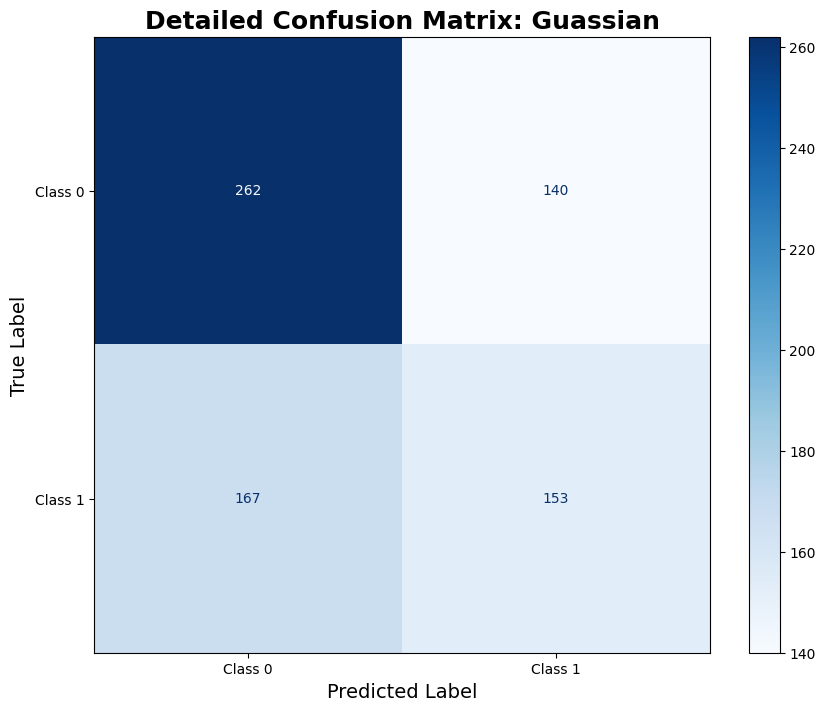

In [ ]:

for name, model in models.items():

    model.fit(X_train, y_train_class)
    y_pred = model.predict(X_test)


    fig, ax = plt.subplots(figsize=(10, 8))


    cm = confusion_matrix(y_test_class, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])

    disp.plot(ax=ax, cmap='Blues', values_format='d')


    ax.set_title(f"Detailed Confusion Matrix: {name}", fontsize=18, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=14)
    ax.set_ylabel('True Label', fontsize=14)

    plt.show()


## 4.6. Final Synthesis: Selecting the Champion Model


Take just the results

In [ ]:


results = []
# Initialize dictionary with the real values
comparison_dict = {"real_values": y_test_class.values.flatten()}

for name, model in models.items():
    # Fit and Predict
    model.fit(X_train, y_train_class)
    y_pred = model.predict(X_test)

    # Store metrics - added 'weighted' to handle multi-class tasks safely
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test_class, y_pred),
        "f1": f1_score(y_test_class, y_pred, average='weighted'),
        "recall": recall_score(y_test_class, y_pred, average='weighted'),
    })

    # Store predictions in dictionary
    comparison_dict[name] = y_pred

# Convert to DataFrames at the end
results_df = pd.DataFrame(results).sort_values(by="f1", ascending=False)
comparaison = pd.DataFrame(comparison_dict)

display(results_df)
display(comparaison)

,model,accuracy,f1,recall
0,RandomForest,0.774238,0.767743,0.774238
1,DecisionTreeClassifier,0.702216,0.702068,0.702216
2,SVC,0.620499,0.589463,0.620499
3,Guassian,0.574792,0.572336,0.574792


,real_values,RandomForest,DecisionTreeClassifier,SVC,Guassian
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,1,1
3,0,0,0,0,0
4,0,0,0,0,1
...,...,...,...,...,...
717,1,0,1,0,0
718,0,0,0,1,1
719,1,0,0,0,1
720,0,0,0,0,0


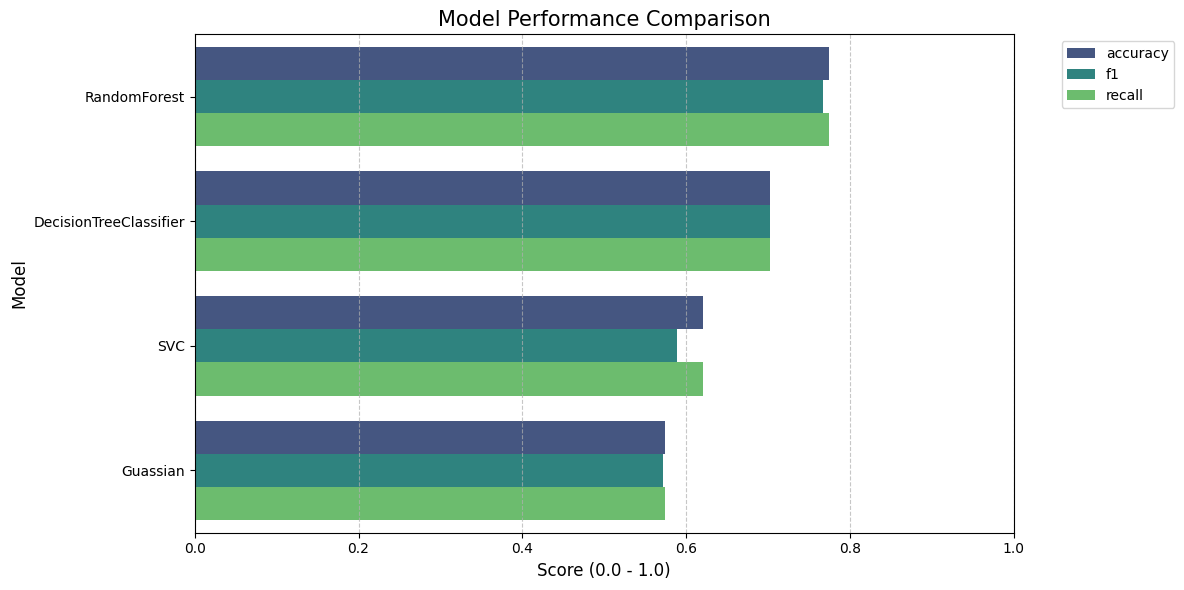

In [ ]:
df_melted = results_df.melt(id_vars="model", var_name="Metric", value_name="Score")

# 2. Plotting
plt.figure(figsize=(12, 6))
sns.barplot(x="Score", y="model", hue="Metric", data=df_melted, palette="viridis")

# 3. Aesthetics
plt.title("Model Performance Comparison", fontsize=15)
plt.xlabel("Score (0.0 - 1.0)", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.xlim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Moves legend outside the plot
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

In [ ]:
X_test.columns

Index(['Year_of_Study', 'Daily_Usage_Hours', 'Trust_in_AI_Tools',
       'Awareness_Level', 'Use_Case_Count', 'Use_Cases_Assignments',
       'Use_Cases_Coding Help', 'Use_Cases_Content Writing',
       'Use_Cases_Doubt Solving', 'Use_Cases_Learning new topics',
       'Use_Cases_MCQ Practice', 'Use_Cases_Notes', 'Use_Cases_Resume Writing',
       'Use_Cases_Exam_Prep', 'AI_Tools_Count', 'AI_Tools_Used_Bard',
       'AI_Tools_Used_ChatGPT', 'AI_Tools_Used_Claude',
       'AI_Tools_Used_Copilot', 'AI_Tools_Used_Gemini',
       'AI_Tools_Used_Midjourney', 'AI_Tools_Used_Other', 'Stream_Arts',
       'Stream_Commerce', 'Stream_Engineering', 'Stream_Hotel-management',
       'Stream_Law', 'Stream_Management', 'Stream_Medical', 'Stream_Pharmacy',
       'Stream_Science', 'Preferred_AI_Tool_ChatGPT',
       'Preferred_AI_Tool_Claude', 'Preferred_AI_Tool_Copilot',
       'Preferred_AI_Tool_Gemini', 'Preferred_AI_Tool_Other',
       'Preferred_AI_Tool_nan', 'Device_Used_Mobile', 'Device_Used_T

In [ ]:
data.columns

Index(['Student_Name', 'College_Name', 'Stream', 'Year_of_Study',
       'AI_Tools_Used', 'Daily_Usage_Hours', 'Use_Cases', 'Trust_in_AI_Tools',
       'Impact_on_Grades', 'Do_Professors_Allow_Use', 'Preferred_AI_Tool',
       'Awareness_Level', 'Willing_to_Pay_for_Access', 'Device_Used',
       'Internet_Access', 'Use_Case_list', 'Use_Case_Count',
       'Use_Cases_Assignments', 'Use_Cases_Coding Help',
       'Use_Cases_Content Writing', 'Use_Cases_Doubt Solving',
       'Use_Cases_Learning new topics', 'Use_Cases_MCQ Practice',
       'Use_Cases_Notes', 'Use_Cases_Resume Writing', 'Use_Cases_Exam_Prep',
       'AI_Tools_Used_list', 'AI_Tools_Count', 'AI_Tools_Used_Bard',
       'AI_Tools_Used_ChatGPT', 'AI_Tools_Used_Claude',
       'AI_Tools_Used_Copilot', 'AI_Tools_Used_Gemini',
       'AI_Tools_Used_Midjourney', 'AI_Tools_Used_Other', 'Stream_Arts',
       'Stream_Commerce', 'Stream_Engineering', 'Stream_Hotel-management',
       'Stream_Law', 'Stream_Management', 'Stream_Medical

# 5. Clustering

### 5.1 Feature Selection

In [ ]:
X_clustering = data_encoded


### 5.2 The Optimal Number of Clusters (Elbow Method)

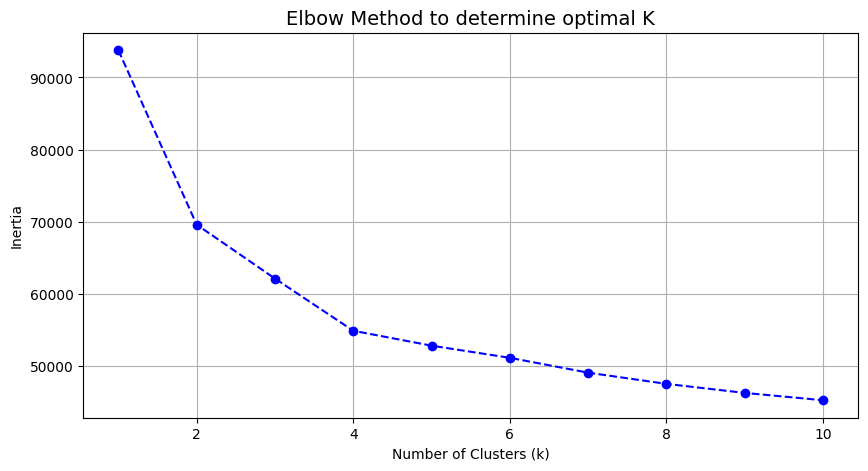

In [ ]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_clustering)
    wcss.append(kmeans.inertia_)

# Affichage du graphique du coude
plt.figure(figsize=(10, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='b')
plt.title('Elbow Method to determine optimal K', fontsize=14)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

### 5.2.1 Training the K-Means Model

a. definition

b.  Model Implementation

In [ ]:
# Assuming k=3 based on your elbow plot
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)

# Assigning each student to a cluster
data['Cluster'] = kmeans.fit_predict(X_clustering)
data_encoded['Cluster']=data['Cluster']
print(f"Success! {optimal_k} student segments have been created.")
data[['Daily_Usage_Hours', 'Cluster']].head()

Success! 4 student segments have been created.


,Daily_Usage_Hours,Cluster
0,0.9,3
1,3.4,1
2,3.6,2
3,2.9,0
4,0.9,3


### 5.2.2 Visualizing Clusters in 2D (PCA)

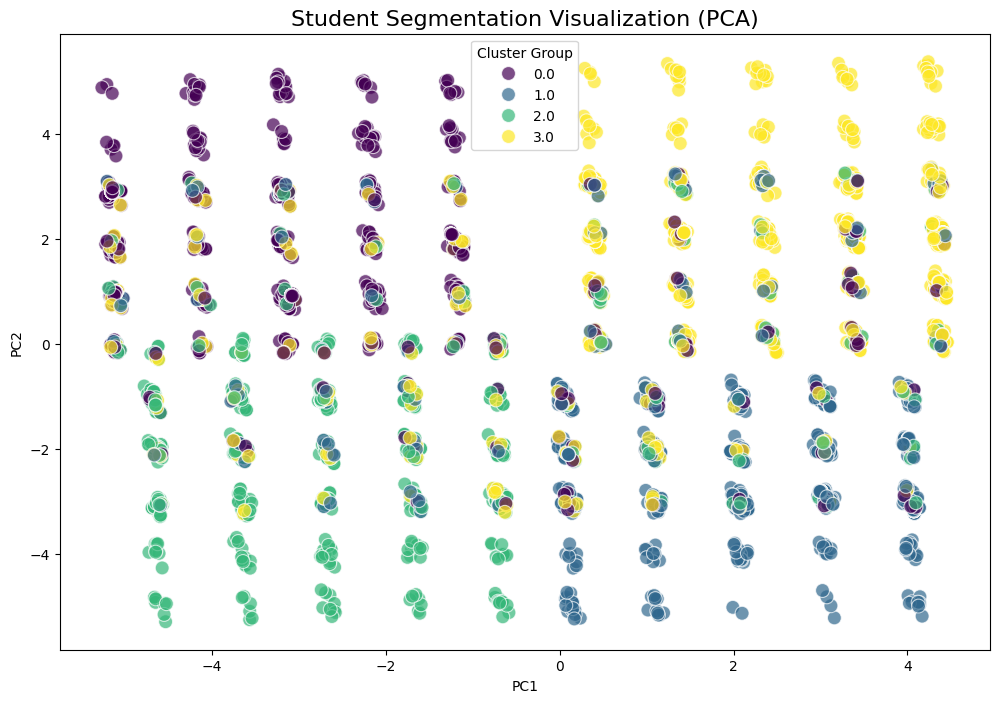

In [ ]:
# Dimensionality Reduction (4D -> 2D)
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_clustering)

# Creating the DataFrame for visualization
pca_df = pd.DataFrame(data=pca_data, columns=['PC1', 'PC2'])
pca_df['Cluster'] = data['Cluster']

# Plot
plt.figure(figsize=(12, 8))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=pca_df, palette='viridis', s=100, alpha=0.7)
plt.title('Student Segmentation Visualization (PCA)', fontsize=16)
plt.legend(title='Cluster Group')
plt.show()

### 5.2.3 Cluster Profiling (Analysis)

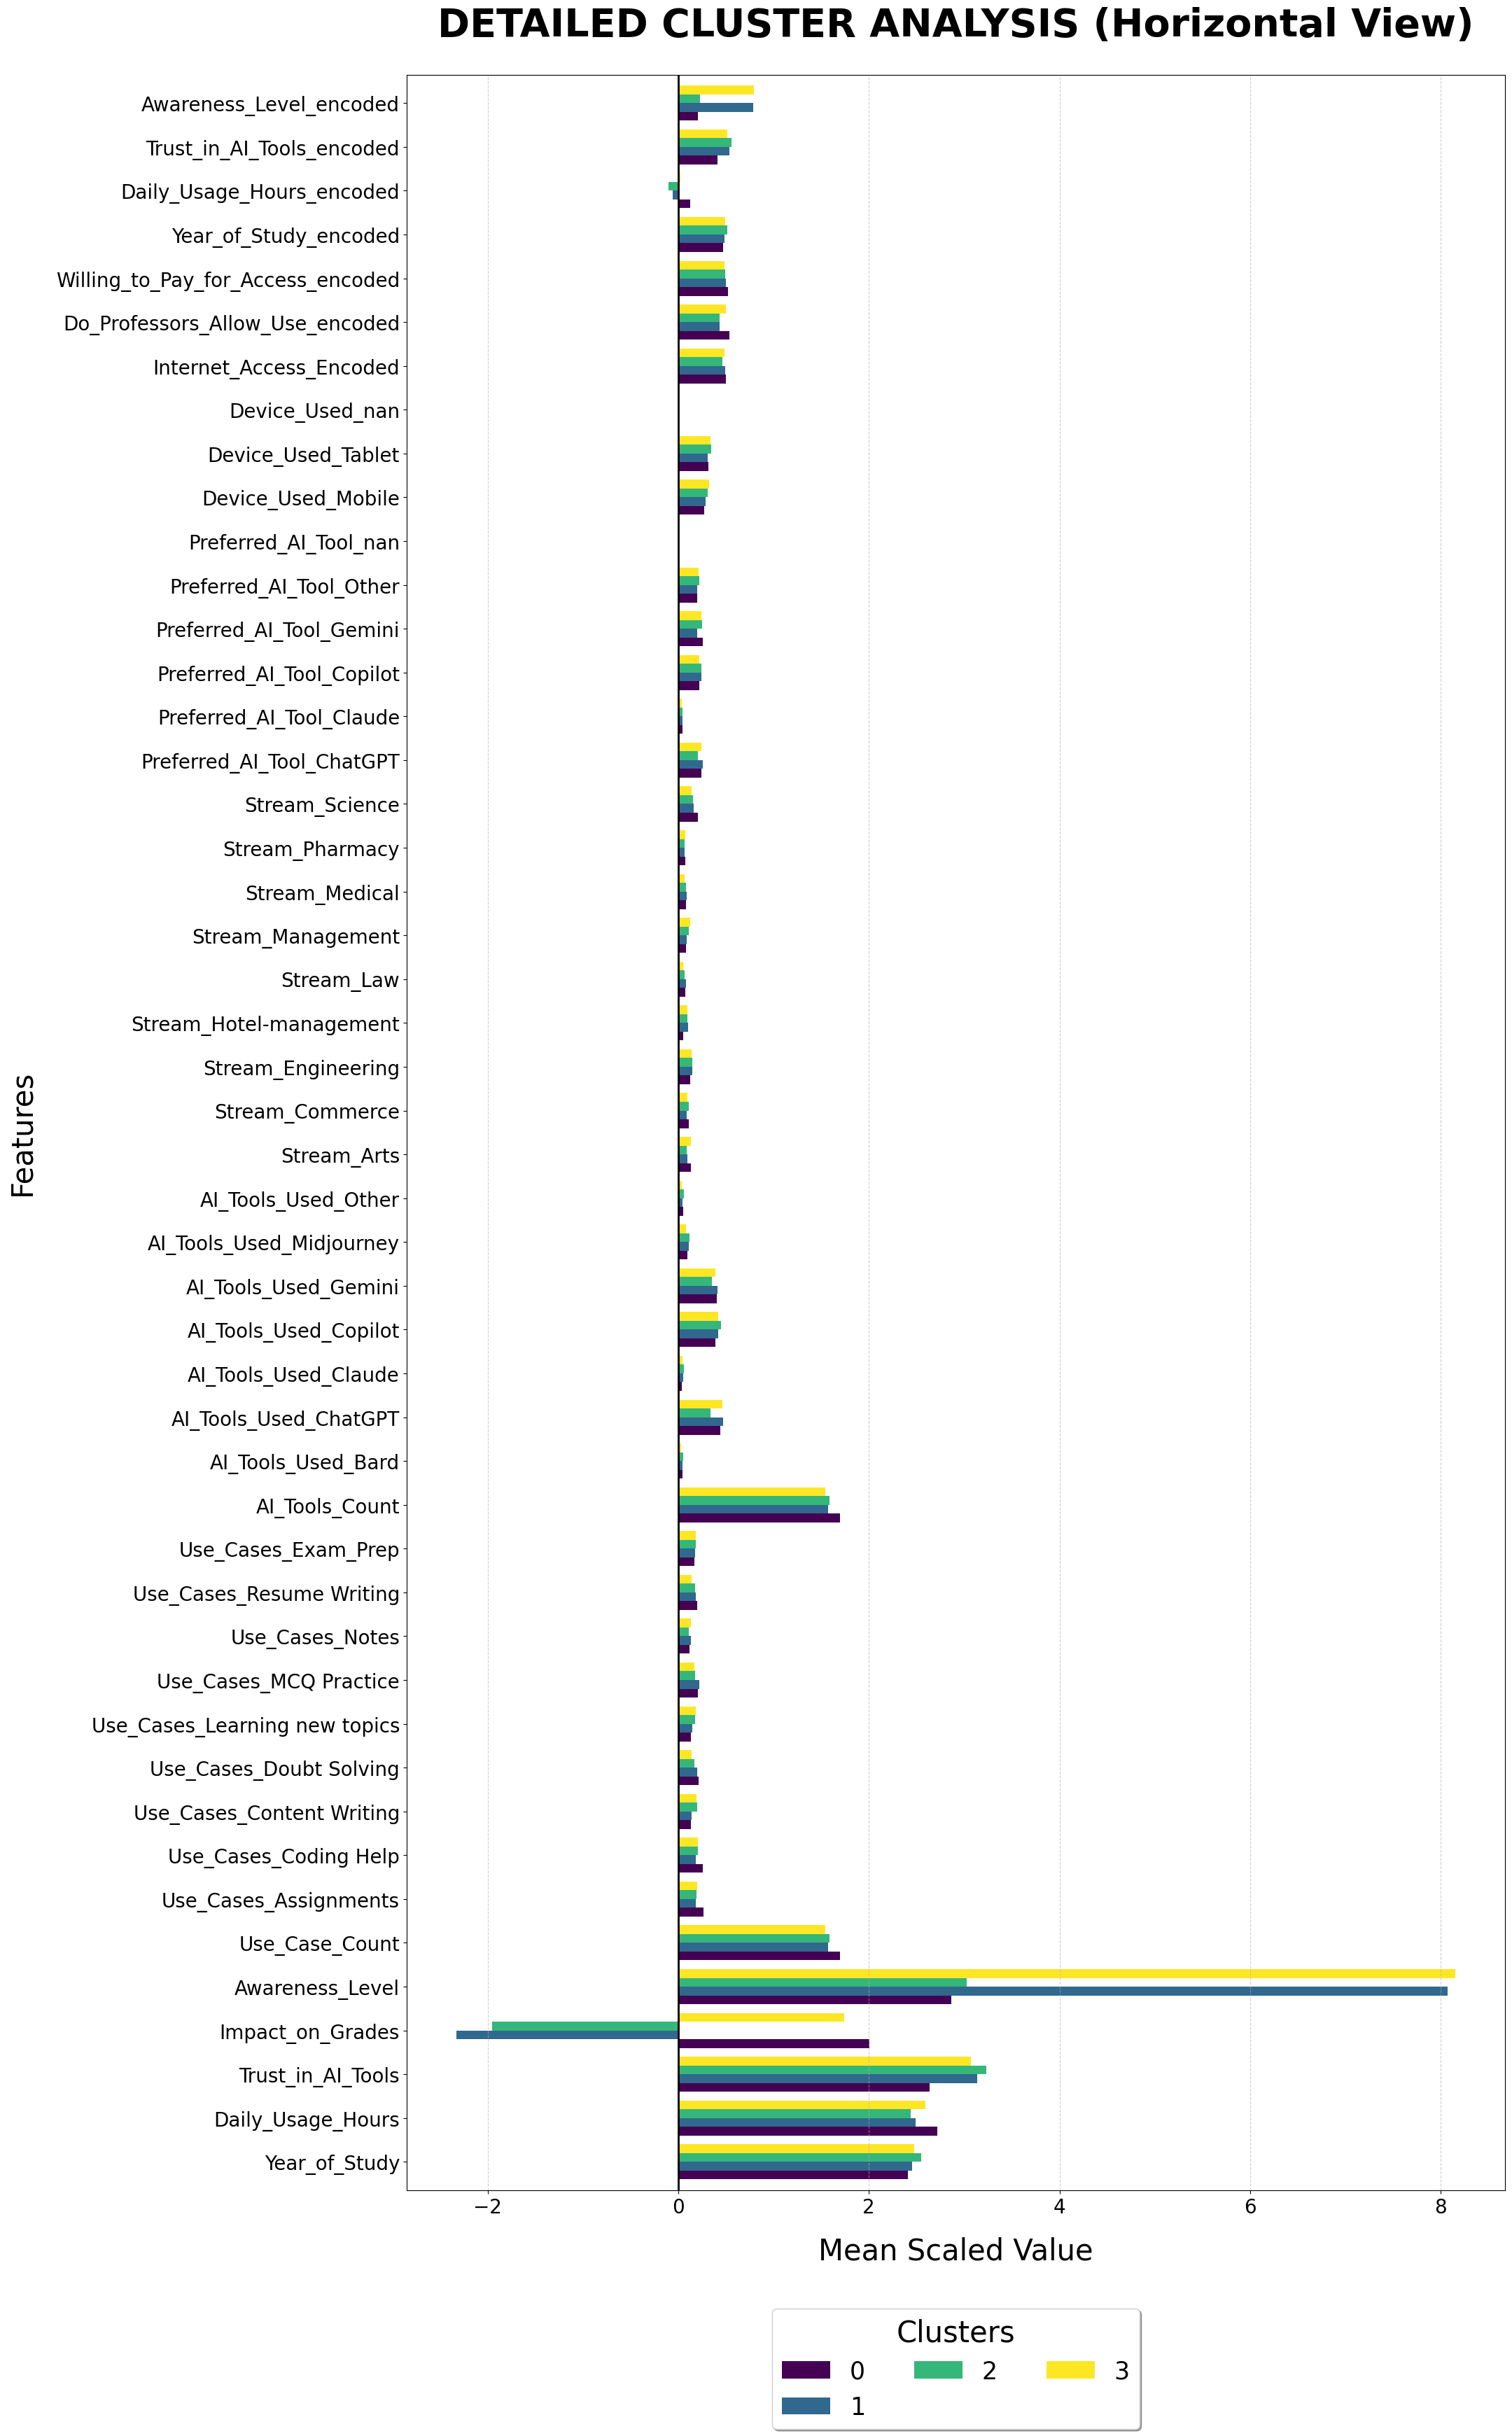

In [ ]:
import matplotlib.pyplot as plt

# 1. Sync the Cluster labels to your encoded DataFrame
data_encoded['Cluster'] = kmeans.labels_

# 2. Group by Cluster and calculate the mean
cluster_analysis = data_encoded.groupby('Cluster').mean(numeric_only=True)

plt.rcParams.update({'font.size': 20})

fig, ax = plt.subplots(figsize=(22, 35), dpi=100)


cluster_analysis.T.plot(kind='barh', ax=ax, width=0.8, colormap='viridis')

plt.title('DETAILED CLUSTER ANALYSIS (Horizontal View)', fontsize=40, fontweight='bold', pad=40)
plt.xlabel('Mean Scaled Value', fontsize=30, labelpad=20)
plt.ylabel('Features', fontsize=30, labelpad=20)

ax.legend(title='Clusters', loc='upper center', bbox_to_anchor=(0.5, -0.05),
          ncol=3, fontsize=25, title_fontsize=30, frameon=True, shadow=True)

plt.axvline(0, color='black', linewidth=2)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)

plt.show()